In [1]:
from datasets import load_dataset, Audio
import pandas as pd

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
# ===== SETUP: run first after every restart or disconnect =====
import os
from google.colab import drive, files
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
!pip -q install jiwer rapidfuzz jellyfish

import re, numpy as np, pandas as pd, torch, jiwer, jellyfish
from rapidfuzz import fuzz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

out = "/content/drive/MyDrive/asr-triage/results"
SIZES = ["small.en", "base.en", "tiny.en"]
EMERGENCY = ["Hard to breath", "Heart hurts"]

# Data: the saved split + all Whisper transcripts
df = pd.read_csv(f"{out}/split.csv")
for size in SIZES:
    df = df.merge(pd.read_csv(f"{out}/asr_all_{size}.csv").rename(columns={"asr": size}), on="id", how="left")
df[SIZES] = df[SIZES].fillna("")
test = df[df.split == "test"].copy()
is_em = test.prompt.isin(EMERGENCY)
print(df.split.value_counts().to_dict(), "| transcripts loaded:", SIZES)

# Your app's safety rules
if not os.path.exists("triage.py"):
    print("Choose src/triage.py from your project folder")
    files.upload()
import triage
def rules_flag(texts):
    return texts.apply(lambda t: triage.assess_text_for_safety(t).level == "emergency")

# WER helpers
def norm(t):
    t = str(t).lower().replace("\u2019", "'")
    return " ".join(re.sub(r"[^a-z0-9' ]", " ", t).split())
def wer(refs, hyps):
    return 100 * jiwer.wer([norm(r) for r in refs], [norm(h) if norm(h) else "<empty>" for h in hyps])

# Keyword matcher (Fix B)
SEEDS = ["heart", "chest", "breath", "breathe", "breathing", "breathless",
         "suffocate", "suffocating", "wheeze", "wheezing", "choke", "choking", "lungs"]
SEED_CODES = {jellyfish.metaphone(s) for s in SEEDS}
def keyword_flag(text, thr=None, phonetic=False):
    for w in re.findall(r"[a-z']+", str(text).lower()):
        if any(s in w for s in SEEDS):
            return True
        if len(w) >= 3:
            if thr and any(fuzz.ratio(w, s) >= thr for s in SEEDS):
                return True
            if phonetic and jellyfish.metaphone(w) in SEED_CODES:
                return True
    return False
def score(frame, flags):
    em = frame.prompt.isin(EMERGENCY)
    return flags[em].mean(), flags[~em].mean()

# DistilBERT helpers
labels = sorted(df.prompt.unique()); l2i = {l: i for i, l in enumerate(labels)}
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
BS, model = 32, None

def batches(texts, ys=None, bs=32, shuffle=False):
    idx = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for i in range(0, len(idx), bs):
        j = idx[i:i + bs]
        enc = tok([texts[k] for k in j], padding=True, truncation=True, max_length=64, return_tensors="pt").to("cuda")
        yield enc, (torch.tensor([ys[k] for k in j]).cuda() if ys is not None else None)

def predict(texts):
    model.eval(); preds = []
    with torch.no_grad():
        for enc, _ in batches(list(texts), bs=128):
            preds += model(**enc).logits.argmax(-1).tolist()
    return [labels[i] for i in preds]

def train_bert(texts, ys, val_texts, val_labels, epochs=3, tag="m"):
    global model
    torch.manual_seed(42); np.random.seed(42)
    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=len(labels)).cuda()
    opt = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(texts) / BS))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    best = -1
    for ep in range(epochs):
        model.train()
        for enc, y in batches(texts, ys, bs=BS, shuffle=True):
            model(**enc, labels=y).loss.backward()
            opt.step(); sched.step(); opt.zero_grad()
        f1 = f1_score(val_labels, predict(val_texts), average="macro")
        print(f"  [{tag}] epoch {ep+1}: val macro-F1 = {f1:.3f}")
        if f1 > best:
            best = f1; torch.save(model.state_dict(), f"/content/bert_{tag}.pt")
    model.load_state_dict(torch.load(f"/content/bert_{tag}.pt"))

print("Setup done. GPU:", torch.cuda.is_available())

{'train': 4817, 'test': 926, 'val': 918} | transcripts loaded: ['small.en', 'base.en', 'tiny.en']


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Setup done. GPU: True


In [2]:
ds = load_dataset("yashtiwari/PaulMooney-Medical-ASR-Data")
print(ds)   # shows the splits and columns

README.md:   0%|          | 0.00/653 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  267MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00011.parquet: reconstructing file:   0%|          |  0.00B /  376MB            

... (21 outputs left out)

Generating train split:   0%|          | 0/381 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/385 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5895 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence', 'prompt', 'speaker_id', 'path'],
        num_rows: 381
    })
    validation: Dataset({
        features: ['id', 'sentence', 'prompt', 'speaker_id', 'path'],
        num_rows: 385
    })
    test: Dataset({
        features: ['id', 'sentence', 'prompt', 'speaker_id', 'path'],
        num_rows: 5895
    })
})


In [4]:
# Text-only table (skips loading the audio, so it's fast)
frames = []
for split in ds:
    d = ds[split].select_columns(["id", "sentence", "prompt", "speaker_id"]).to_pandas()
    d["orig_split"] = split
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

pd.set_option("display.max_colwidth", 120)
print(df.sample(20, random_state=42)[["prompt", "sentence", "speaker_id"]])

                prompt  \
5265  Hair falling out   
3315       Muscle pain   
752           Ear ache   
3187         Knee pain   
6026       Muscle pain   
5721       Heart hurts   
6168    Hard to breath   
233     Emotional pain   
3319       Muscle pain   
5668             Cough   
5171  Hair falling out   
4836     Shoulder pain   
1149    Infected wound   
6032        Joint pain   
4614      Stomach ache   
6017              Acne   
611        Muscle pain   
3149        Open wound   
1328  Hair falling out   
1433     Shoulder pain   

                                                                                   sentence  \
5265                                                  My hair is falling out in huge amount   
3315                                          The pain feels like it's right below the skin   
752                                                       I get an ear ache when it is cold   
3187                                           I could not exercise becau

In [5]:
print("\nTotal clips:      ", len(df))
print("Unique sentences: ", df.sentence.str.lower().str.strip().nunique())
print("Unique speakers:  ", df.speaker_id.nunique())
print("\nClips per label:\n", df.prompt.value_counts())


Total clips:       6661
Unique sentences:  703
Unique speakers:   124

Clips per label:
 prompt
Acne                  328
Shoulder pain         320
Joint pain            318
Infected wound        306
Knee pain             305
Cough                 293
Feeling dizzy         283
Muscle pain           282
Heart hurts           273
Ear ache              270
Hair falling out      264
Head ache             263
Feeling cold          263
Skin issue            262
Stomach ache          261
Back pain             259
Neck pain             251
Internal pain         248
Blurry vision         246
Body feels weak       241
Hard to breath        233
Emotional pain        231
Injury from sports    230
Foot ache             223
Open wound            208
Name: count, dtype: int64


In [6]:
#To listen to one clip and check that the audio matches its text:\

from IPython.display import Audio as Play
raw = ds["test"].cast_column("path", Audio(decode=False))
ex = raw[0]
print(ex["sentence"], "|", ex["prompt"])
Play(data=ex["path"]["bytes"])

All my body is in a bad case and i need a good treatment | Joint pain


In [8]:
#To save our results to Google Drive so they survive Colab resets:

from google.colab import drive
import os
drive.mount("/content/drive")
out = "/content/drive/MyDrive/asr-triage/results"
os.makedirs(out, exist_ok=True)
df.to_csv(f"{out}/metadata.csv", index=False)
df.prompt.value_counts().to_csv(f"{out}/label_counts.csv")

Mounted at /content/drive


# Fair train/val/test split

In [1]:
import pandas as pd, os
from sklearn.model_selection import StratifiedGroupKFold

out = "/content/drive/MyDrive/asr-triage/results"
df = pd.read_csv(f"{out}/metadata.csv")
df["sent_key"] = (df.sentence.str.lower().str.replace(r"[^a-z ]", "", regex=True)
                  .str.split().str.join(" "))

print("Unique sentences per label:\n", df.groupby("prompt").sent_key.nunique().sort_values())

# ~14% test, then ~14% val, keeping every label in every split where possible
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trval_i, te_i = next(sgkf.split(df, df.prompt, groups=df.sent_key))
trval = df.iloc[trval_i]
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_i, va_i = next(sgkf2.split(trval, trval.prompt, groups=trval.sent_key))

df["split"] = "test"
df.loc[trval.index[tr_i], "split"] = "train"
df.loc[trval.index[va_i], "split"] = "val"

print(df.split.value_counts())
for a, b in [("train","val"), ("train","test"), ("val","test")]:
    print(f"{a}/{b} shared sentences:", len(set(df[df.split==a].sent_key) & set(df[df.split==b].sent_key)))
ct = pd.crosstab(df.prompt, df.split)
print(ct)
print("Labels missing from a split:", ct[(ct == 0).any(axis=1)].index.tolist())
df.to_csv(f"{out}/split.csv", index=False)

Unique sentences per label:
 prompt
Open wound            21
Emotional pain        24
Neck pain             25
Hard to breath        25
Feeling dizzy         26
Blurry vision         26
Body feels weak       26
Back pain             26
Internal pain         26
Injury from sports    27
Feeling cold          27
Foot ache             27
Stomach ache          27
Head ache             27
Ear ache              28
Hair falling out      28
Skin issue            29
Muscle pain           29
Cough                 30
Heart hurts           31
Knee pain             32
Acne                  33
Infected wound        34
Joint pain            34
Shoulder pain         35
Name: sent_key, dtype: int64
split
train    4817
test      926
val       918
Name: count, dtype: int64
train/val shared sentences: 0
train/test shared sentences: 0
val/test shared sentences: 0
split               test  train  val
prompt                              
Acne                  61    229   38
Back pain             55    161   4

# TF-IDF baseline on the correct transcripts

Emergency labels: ['Hard to breath', 'Heart hurts']
Val macro-F1 by C: {0.5: 0.687, 1: 0.68, 2: 0.669, 5: 0.662, 10: 0.662} -> best C = 0.5
{'source': 'Correct (human)', 'accuracy': 0.7084233261339092, 'macro_f1': 0.621583571625676, 'emergency_recall': np.float64(0.5604395604395604)}
Random split (leaky): {'source': 'random split', 'accuracy': 0.992, 'macro_f1': 0.9922993529375777, 'emergency_recall': np.float64(0.9868421052631579)}
Sentences shared between train and test: 546


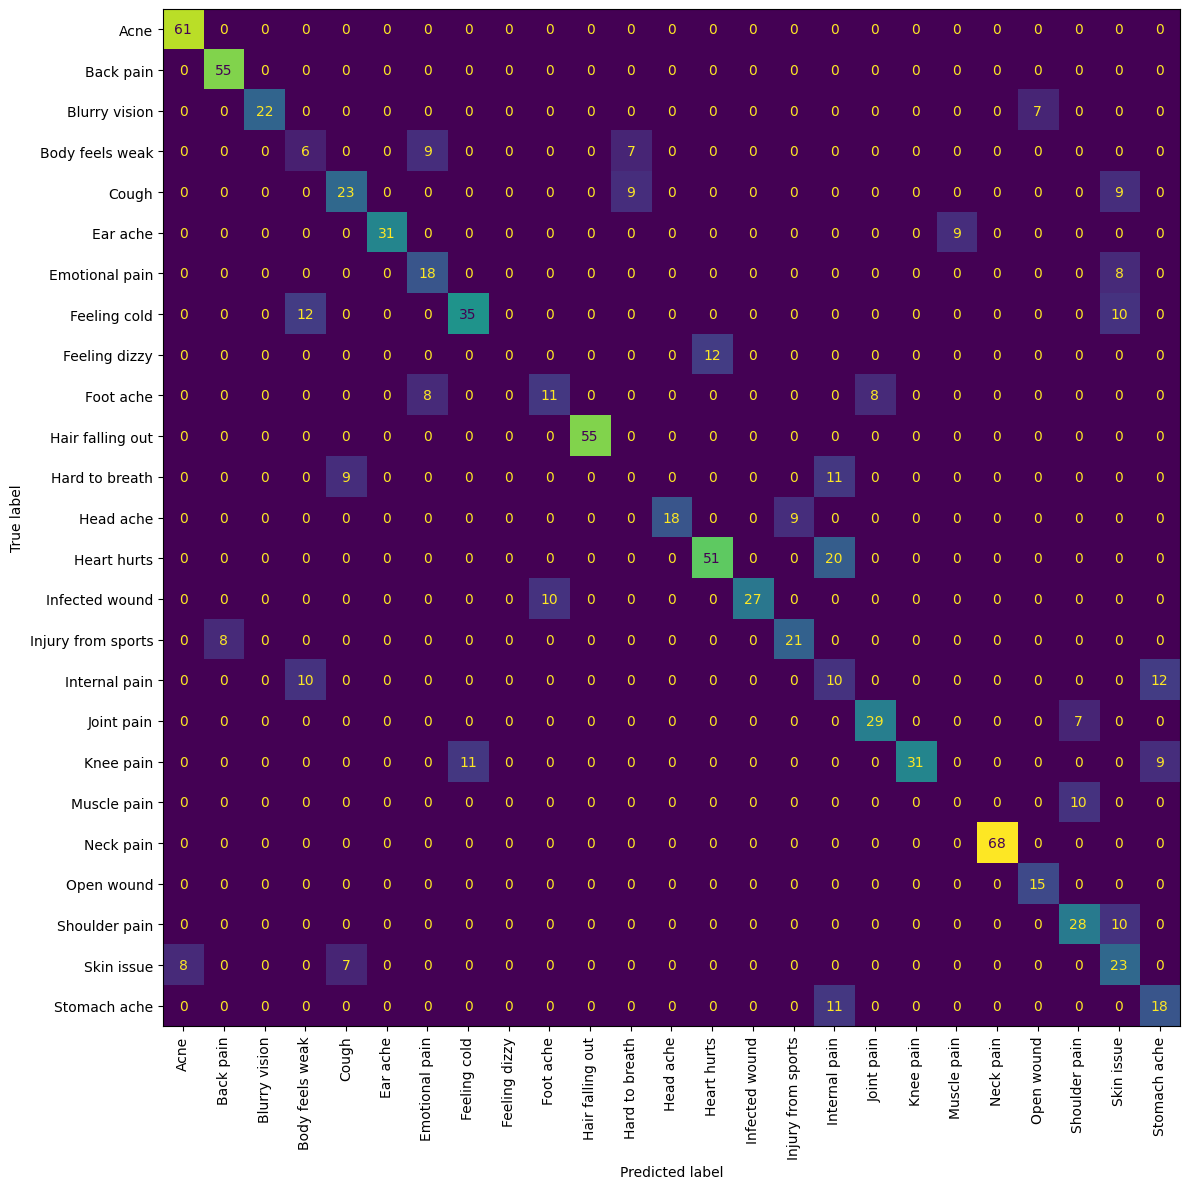

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt, joblib

train, val, test = (df[df.split==s] for s in ["train", "val", "test"])

EMERGENCY = sorted(p for p in df.prompt.unique() if "heart" in p.lower() or "breath" in p.lower())
print("Emergency labels:", EMERGENCY)

def make_model(C):
    # No stop-word removal on purpose: words like "not" and "can't" matter for symptoms
    return make_pipeline(
        TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=42))

# Pick C on the validation set only
scores = {C: f1_score(val.prompt, make_model(C).fit(train.sentence, train.prompt).predict(val.sentence), average="macro")
          for C in [0.5, 1, 2, 5, 10]}
best_C = max(scores, key=scores.get)
print("Val macro-F1 by C:", {k: round(v, 3) for k, v in scores.items()}, "-> best C =", best_C)
tfidf = make_model(best_C).fit(train.sentence, train.prompt)

def evaluate(model, texts, labels, source):
    pred = pd.Series(model.predict(texts), index=labels.index)
    em = labels.isin(EMERGENCY)
    return {"source": source,
            "accuracy": accuracy_score(labels, pred),
            "macro_f1": f1_score(labels, pred, average="macro"),
            # an emergency clip counts as caught if it is predicted as ANY emergency label
            "emergency_recall": pred[em].isin(EMERGENCY).mean()}

row = evaluate(tfidf, test.sentence, test.prompt, "Correct (human)")
print(row)
pd.DataFrame([row]).to_csv(f"{out}/table1_tfidf.csv", index=False)
joblib.dump(tfidf, f"{out}/tfidf_model.joblib")

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(test.prompt, tfidf.predict(test.sentence),
                                        xticks_rotation=90, ax=ax, colorbar=False)
plt.tight_layout(); plt.savefig(f"{out}/confusion_tfidf_correct.png", dpi=150)
from sklearn.model_selection import train_test_split
r_tr, r_te = train_test_split(df, test_size=0.15, stratify=df.prompt, random_state=42)
leaky = make_model(best_C).fit(r_tr.sentence, r_tr.prompt)
print("Random split (leaky):", evaluate(leaky, r_te.sentence, r_te.prompt, "random split"))
print("Sentences shared between train and test:", len(set(r_tr.sent_key) & set(r_te.sent_key)))

# Start Whisper on the test audio

In [3]:
import io, os, time, torch, numpy as np, pandas as pd, soundfile as sf, librosa
from datasets import load_dataset, Audio
from transformers import pipeline

out = "/content/drive/MyDrive/asr-triage/results"
ds = load_dataset("yashtiwari/PaulMooney-Medical-ASR-Data")

def load16k(a):
    data, sr = sf.read(io.BytesIO(a) if isinstance(a, bytes) else a, dtype="float32")
    if data.ndim > 1:
        data = data.mean(axis=1)
    if sr != 16000:
        data = librosa.resample(data, orig_sr=sr, target_sr=16000)
    return data

# Decode every clip once, reuse for all three model sizes
ids, arrays = [], []
for s in ds:
    for ex in ds[s].cast_column("path", Audio(decode=False)):
        a = ex["path"]
        ids.append(ex["id"])
        arrays.append(load16k(a["bytes"] or a["path"]))
print(len(ids), "clips decoded")

for size in ["tiny.en", "base.en", "small.en"]:
    path = f"{out}/asr_all_{size}.csv"
    if os.path.exists(path):
        print("already done:", size); continue
    try:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", dtype=torch.float16, device=0)
    except TypeError:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", torch_dtype=torch.float16, device=0)
    texts, t0 = [], time.time()
    for start in range(0, len(arrays), 512):
        batch = [{"raw": x, "sampling_rate": 16000} for x in arrays[start:start + 512]]
        texts += [o["text"].strip() for o in asr(batch, batch_size=32)]
        print(size, len(texts), "/", len(arrays), f"{time.time()-t0:.0f}s")
    pd.DataFrame({"id": ids, "asr": texts}).to_csv(path, index=False)
    del asr; torch.cuda.empty_cache()
    print("saved", size)

6661 clips decoded


config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

... (36 outputs left out)

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

small.en 512 / 6661 122s
small.en 1024 / 6661 242s
small.en 1536 / 6661 365s
small.en 2048 / 6661 584s
small.en 2560 / 6661 701s
small.en 3072 / 6661 821s
small.en 3584 / 6661 947s
small.en 4096 / 6661 1066s
small.en 4608 / 6661 1184s
small.en 5120 / 6661 1304s
small.en 5632 / 6661 1420s
small.en 6144 / 6661 1541s
small.en 6656 / 6661 1664s
small.en 6661 / 6661 1665s
saved small.en


Table 1

In [ ]:
!pip -q install jiwer
import re, jiwer, joblib, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from google.colab import files

import os
if not os.path.exists("triage.py"):
    files.upload()     # choose src/triage.py

out = "/content/drive/MyDrive/asr-triage/results"
SIZES = ["small.en", "base.en", "tiny.en"]          # best to worst
EMERGENCY = ["Hard to breath", "Heart hurts"]

df = pd.read_csv(f"{out}/split.csv")
for size in SIZES:
    asr = pd.read_csv(f"{out}/asr_all_{size}.csv").rename(columns={"asr": size})
    df = df.merge(asr, on="id", how="left")
df[SIZES] = df[SIZES].fillna("")
df.to_csv(f"{out}/all_transcripts.csv", index=False)

test = df[df.split == "test"].copy()
is_em = test.prompt.isin(EMERGENCY)
tfidf = joblib.load(f"{out}/tfidf_model.joblib")

def norm(t):
    t = str(t).lower().replace("\u2019", "'")
    t = re.sub(r"[^a-z0-9' ]", " ", t)
    return " ".join(t.split())

def wer(refs, hyps):
    return 100 * jiwer.wer([norm(r) for r in refs], [norm(h) if norm(h) else "<empty>" for h in hyps])

def rules_flag(texts):
    return texts.apply(lambda t: triage.assess_text_for_safety(t).level == "emergency")

rows = []
for name, col in [("Correct (human)", "sentence")] + [(f"Whisper {s}", s) for s in SIZES]:
    texts = test[col]
    pred = pd.Series(tfidf.predict(texts), index=test.index)
    test[f"pred_{col}"] = pred
    clf_em, rule_em = pred.isin(EMERGENCY), rules_flag(texts)
    rows.append({
        "source": name,
        "WER_%": 0.0 if col == "sentence" else wer(test.sentence, texts),
        "WER_emergency_%": 0.0 if col == "sentence" else wer(test.sentence[is_em], texts[is_em]),
        "accuracy": accuracy_score(test.prompt, pred),
        "macro_f1": f1_score(test.prompt, pred, average="macro"),
        "emerg_recall_classifier": clf_em[is_em].mean(),
        "emerg_recall_rules": rule_em[is_em].mean(),
        "emerg_recall_either": (clf_em | rule_em)[is_em].mean(),
        "false_alarm_either": (clf_em | rule_em)[~is_em].mean(),
    })

table1 = pd.DataFrame(rows).round(3)
pd.set_option("display.width", 200)
print(table1.to_string(index=False))
table1.to_csv(f"{out}/table1.csv", index=False)

# Figure 1: performance vs WER
fig, ax = plt.subplots(figsize=(6, 4))
for col, label in [("macro_f1", "Symptom macro-F1"),
                   ("emerg_recall_classifier", "Emergency recall (classifier)"),
                   ("emerg_recall_either", "Emergency recall (classifier or rules)")]:
    ax.plot(table1["WER_%"], table1[col], marker="o", label=label)
for _, r in table1.iterrows():
    ax.annotate(r["source"].replace("Whisper ", ""), (r["WER_%"], r["macro_f1"]),
                textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("Word error rate (%)"); ax.set_ylabel("Score"); ax.set_ylim(0, 1)
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{out}/fig1_performance_vs_wer.png", dpi=200); plt.show()

# Examples for the report: emergency clips where Whisper changed the outcome
ex = test[is_em][["prompt", "sentence", "tiny.en", "pred_sentence", "pred_tiny.en"]]
changed = ex[ex.pred_sentence.isin(EMERGENCY) & ~ex["pred_tiny.en"].isin(EMERGENCY)]
pd.set_option("display.max_colwidth", 90)
print(f"\nEmergency clips caught on correct text but missed on tiny.en: {len(changed)}")
print(changed.head(10).to_string(index=False))
changed.to_csv(f"{out}/examples_missed_after_asr.csv", index=False)

# Which emergency sentences do the rules catch at all?
print("\nRules catch on correct text, by label:")
print(test[is_em].assign(rule=rules_flag(test[is_em].sentence)).groupby("prompt").rule.mean())

Block 5: DistilBERT and keyword survival

In [4]:
import numpy as np, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42); np.random.seed(42)
train, val = df[df.split == "train"], df[df.split == "val"]
labels = sorted(df.prompt.unique()); l2i = {l: i for i, l in enumerate(labels)}

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=len(labels)).cuda()

def batches(texts, ys=None, bs=32, shuffle=False):
    idx = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for i in range(0, len(idx), bs):
        j = idx[i:i + bs]
        enc = tok([texts[k] for k in j], padding=True, truncation=True, max_length=64, return_tensors="pt").to("cuda")
        yield enc, (torch.tensor([ys[k] for k in j]).cuda() if ys is not None else None)

def predict(texts):
    model.eval(); preds = []
    with torch.no_grad():
        for enc, _ in batches(list(texts), bs=128):
            preds += model(**enc).logits.argmax(-1).tolist()
    return [labels[i] for i in preds]

Xtr, ytr = list(train.sentence), [l2i[l] for l in train.prompt]
EPOCHS, BS = 4, 32
opt = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
steps = EPOCHS * int(np.ceil(len(Xtr) / BS))
sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

best = -1
for ep in range(EPOCHS):
    model.train()
    for enc, y in batches(Xtr, ytr, bs=BS, shuffle=True):
        model(**enc, labels=y).loss.backward()
        opt.step(); sched.step(); opt.zero_grad()
    f1 = f1_score(val.prompt, predict(val.sentence), average="macro")
    print(f"epoch {ep+1}: val macro-F1 = {f1:.3f}")
    if f1 > best:
        best = f1; torch.save(model.state_dict(), "/content/bert_best.pt")
model.load_state_dict(torch.load("/content/bert_best.pt"))

rows = []
for name, col in [("Correct (human)", "sentence")] + [(f"Whisper {s}", s) for s in SIZES]:
    pred = pd.Series(predict(test[col]), index=test.index)
    test[f"bert_{col}"] = pred
    em = pred.isin(EMERGENCY)
    rows.append({"source": name, "accuracy": accuracy_score(test.prompt, pred),
                 "macro_f1": f1_score(test.prompt, pred, average="macro"),
                 "emerg_recall": em[is_em].mean(), "false_alarm": em[~is_em].mean()})
bert_table = pd.DataFrame(rows).round(3)
print("\nDistilBERT:\n", bert_table.to_string(index=False))
bert_table.to_csv(f"{out}/table1_distilbert.csv", index=False)

# Safety-keyword survival: when the correct text contains the keyword, does Whisper keep it?
kw_rows = []
for kw in ["heart", "breath"]:
    has = test.sentence.str.lower().str.contains(kw)
    for s in SIZES:
        kw_rows.append({"keyword": kw, "whisper": s, "clips_with_keyword": int(has.sum()),
                        "keyword_kept_%": round(100 * test.loc[has, s].str.lower().str.contains(kw).mean(), 1)})
kw_table = pd.DataFrame(kw_rows)
print("\nKeyword survival:\n", kw_table.to_string(index=False))
kw_table.to_csv(f"{out}/keyword_survival.csv", index=False)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: val macro-F1 = 0.762
epoch 2: val macro-F1 = 0.784
epoch 3: val macro-F1 = 0.732
epoch 4: val macro-F1 = 0.739

DistilBERT:
           source  accuracy  macro_f1  emerg_recall  false_alarm
 Correct (human)     0.856     0.798         0.802        0.011
Whisper small.en     0.756     0.697         0.714        0.029
 Whisper base.en     0.740     0.683         0.714        0.026
 Whisper tiny.en     0.699     0.635         0.692        0.036

Keyword survival:
 keyword  whisper  clips_with_keyword  keyword_kept_%
  heart small.en                  51            86.3
  heart  base.en                  51            88.2
  heart  tiny.en                  51            86.3
 breath small.en                  20            95.0
 breath  base.en                  20            80.0
 breath  tiny.en                  20            75.0


Block 6: Fix B, an emergency matcher built for Whisper’s errors

In [5]:
!pip -q install rapidfuzz jellyfish
from rapidfuzz import fuzz
import jellyfish

# Seed words come from the meaning of the two emergency labels, not from test data
SEEDS = ["heart", "chest", "breath", "breathe", "breathing", "breathless",
         "suffocate", "suffocating", "wheeze", "wheezing", "choke", "choking", "lungs"]
SEED_CODES = {jellyfish.metaphone(s) for s in SEEDS}

def keyword_flag(text, thr=None, phonetic=False):
    for w in re.findall(r"[a-z']+", str(text).lower()):
        if any(s in w for s in SEEDS):                       # "heartache", "breathing"
            return True
        if len(w) >= 3:
            if thr and any(fuzz.ratio(w, s) >= thr for s in SEEDS):
                return True
            if phonetic and jellyfish.metaphone(w) in SEED_CODES:
                return True
    return False

CONFIGS = {"keyword": {}, "fuzzy90": {"thr": 90}, "fuzzy80": {"thr": 80}, "fuzzy70": {"thr": 70},
           "phonetic": {"phonetic": True}, "fuzzy80+phonetic": {"thr": 80, "phonetic": True}}

def score(frame, flags):
    em = frame.prompt.isin(EMERGENCY)
    return flags[em].mean(), flags[~em].mean()

# 1) Choose on VALIDATION (Whisper base.en transcripts)
val = df[df.split == "val"]
print("Validation, Whisper base.en:")
for name, cfg in CONFIGS.items():
    r, f = score(val, val["base.en"].apply(lambda t: keyword_flag(t, **cfg)))
    print(f"  {name:18s} recall={r:.3f}  false_alarm={f:.3f}")

# 2) Report on TEST, alone and combined with DistilBERT
rows = []
for name, col in [("Correct (human)", "sentence")] + [(f"Whisper {s}", s) for s in SIZES]:
    bert_em = test[f"bert_{col}"].isin(EMERGENCY)
    r, f = score(test, bert_em)
    rows.append({"source": name, "method": "DistilBERT only", "recall": r, "false_alarm": f})
    for mname, cfg in CONFIGS.items():
        kw = test[col].apply(lambda t: keyword_flag(t, **cfg))
        r, f = score(test, kw)
        rows.append({"source": name, "method": mname, "recall": r, "false_alarm": f})
        r, f = score(test, kw | bert_em)
        rows.append({"source": name, "method": f"DistilBERT + {mname}", "recall": r, "false_alarm": f})
table2 = pd.DataFrame(rows).round(3)
print("\n", table2.pivot(index="method", columns="source", values="recall").to_string())
print("\nFalse alarms:\n", table2.pivot(index="method", columns="source", values="false_alarm").to_string())
table2.to_csv(f"{out}/table2_emergency_matchers.csv", index=False)

Validation, Whisper base.en:
  keyword            recall=0.768  false_alarm=0.022
  fuzzy90            recall=0.768  false_alarm=0.022
  fuzzy80            recall=0.768  false_alarm=0.030
  fuzzy70            recall=0.768  false_alarm=0.171
  phonetic           recall=0.768  false_alarm=0.122
  fuzzy80+phonetic   recall=0.768  false_alarm=0.129

 source                         Correct (human)  Whisper base.en  Whisper small.en  Whisper tiny.en
method                                                                                            
DistilBERT + fuzzy70                     0.901            0.835             0.835            0.835
DistilBERT + fuzzy80                     0.901            0.802             0.813            0.780
DistilBERT + fuzzy80+phonetic            0.901            0.824             0.824            0.791
DistilBERT + fuzzy90                     0.901            0.802             0.802            0.780
DistilBERT + keyword                     0.901           

train DistilBERT on Whisper transcripts too

In [6]:
def train_bert(texts, ys, val_texts, val_labels, epochs=3, tag="aug"):
    global model
    torch.manual_seed(42); np.random.seed(42)
    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=len(labels)).cuda()
    opt = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(texts) / BS))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    best = -1
    for ep in range(epochs):
        model.train()
        for enc, y in batches(texts, ys, bs=BS, shuffle=True):
            model(**enc, labels=y).loss.backward()
            opt.step(); sched.step(); opt.zero_grad()
        f1 = f1_score(val_labels, predict(val_texts), average="macro")
        print(f"epoch {ep+1}: val macro-F1 = {f1:.3f}")
        if f1 > best:
            best = f1; torch.save(model.state_dict(), f"/content/bert_{tag}.pt")
    model.load_state_dict(torch.load(f"/content/bert_{tag}.pt"))

cols = ["sentence"] + SIZES
aug_texts = [t for c in cols for t in train[c]]
aug_ys = [l2i[l] for c in cols for l in train.prompt]
val_texts = [t for c in cols for t in val[c]]
val_labels = [l for c in cols for l in val.prompt]
train_bert(aug_texts, aug_ys, val_texts, val_labels, epochs=3)

rows = []
for name, col in [("Correct (human)", "sentence")] + [(f"Whisper {s}", s) for s in SIZES]:
    pred = pd.Series(predict(test[col]), index=test.index)
    test[f"bertaug_{col}"] = pred
    em = pred.isin(EMERGENCY)
    rows.append({"source": name, "accuracy": accuracy_score(test.prompt, pred),
                 "macro_f1": f1_score(test.prompt, pred, average="macro"),
                 "emerg_recall": em[is_em].mean(), "false_alarm": em[~is_em].mean()})
aug_table = pd.DataFrame(rows).round(3)
print("\nDistilBERT trained with Whisper transcripts:\n", aug_table.to_string(index=False))
print("\nFor comparison, trained on correct text only:\n", bert_table.to_string(index=False))
aug_table.to_csv(f"{out}/table3_distilbert_asr_augmented.csv", index=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: val macro-F1 = 0.680
epoch 2: val macro-F1 = 0.658
epoch 3: val macro-F1 = 0.647

DistilBERT trained with Whisper transcripts:
           source  accuracy  macro_f1  emerg_recall  false_alarm
 Correct (human)     0.874     0.809         1.000        0.011
Whisper small.en     0.798     0.731         0.868        0.019
 Whisper base.en     0.784     0.737         0.901        0.023
 Whisper tiny.en     0.758     0.707         0.857        0.024

For comparison, trained on correct text only:
           source  accuracy  macro_f1  emerg_recall  false_alarm
 Correct (human)     0.856     0.798         0.802        0.011
Whisper small.en     0.756     0.697         0.714        0.029
 Whisper base.en     0.740     0.683         0.714        0.026
 Whisper tiny.en     0.699     0.635         0.692        0.036


Block 8: final system, keyword matching added to Fix A (seconds)

In [ ]:
rows = []
for name, col in [("Correct (human)", "sentence")] + [(f"Whisper {s}", s) for s in SIZES]:
    aug_em = test[f"bertaug_{col}"].isin(EMERGENCY)
    kw = test[col].apply(keyword_flag)
    for method, flags in [("DistilBERT+ASR", aug_em), ("DistilBERT+ASR + keyword", aug_em | kw)]:
        r, f = score(test, flags)
        rows.append({"source": name, "method": method, "recall": round(r, 3), "false_alarm": round(f, 3)})
final = pd.DataFrame(rows)
print(final.pivot(index="method", columns="source", values="recall").to_string())
print(final.pivot(index="method", columns="source", values="false_alarm").to_string())
final.to_csv(f"{out}/table4_final_system.csv", index=False)

Block 9: repeat everything on 5 different splits for error bars (about 40–60 min on GPU)

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

def make_split(frame, seed):
    s1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    trv, te = next(s1.split(frame, frame.prompt, groups=frame.sent_key))
    trval = frame.iloc[trv]
    s2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    tr, va = next(s2.split(trval, trval.prompt, groups=trval.sent_key))
    sp = pd.Series("test", index=frame.index)
    sp[trval.index[tr]] = "train"; sp[trval.index[va]] = "val"
    return sp

rep_path = f"{out}/repeated_splits.csv"
rep = pd.read_csv(rep_path) if os.path.exists(rep_path) else pd.DataFrame()
cols = ["sentence"] + SIZES
src_name = {"sentence": "Correct (human)", **{s: f"Whisper {s}" for s in SIZES}}

for seed in [42, 1, 2, 3, 4]:
    if len(rep) and seed in set(rep.seed):
        print("seed", seed, "already done"); continue
    sp = make_split(df, seed)
    tr, va, te = df[sp == "train"], df[sp == "val"], df[sp == "test"]
    em = te.prompt.isin(EMERGENCY)
    rows = []

    def record(method, col, pred=None, flags=None):
        if flags is None:
            flags = pd.Series(pred, index=te.index).isin(EMERGENCY)
        rows.append({"seed": seed, "method": method, "source": src_name[col],
                     "macro_f1": f1_score(te.prompt, pred, average="macro") if pred is not None else np.nan,
                     "emerg_recall": flags[em].mean(), "false_alarm": flags[~em].mean()})
        return flags

    # TF-IDF (C chosen on validation)
    best_C = max([0.5, 1, 2, 5], key=lambda C: f1_score(va.prompt, make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=42)
    ).fit(tr.sentence, tr.prompt).predict(va.sentence), average="macro"))
    tf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                       LogisticRegression(C=best_C, max_iter=3000, class_weight="balanced", random_state=42)).fit(tr.sentence, tr.prompt)
    for c in cols:
        record("TF-IDF", c, tf.predict(te[c]))

    # DistilBERT, correct text only
    train_bert(list(tr.sentence), [l2i[l] for l in tr.prompt], list(va.sentence), list(va.prompt), epochs=3, tag=f"base{seed}")
    for c in cols:
        record("DistilBERT", c, predict(te[c]))

    # DistilBERT + Whisper transcripts (Fix A), then + keyword
    train_bert([t for c in cols for t in tr[c]], [l2i[l] for c in cols for l in tr.prompt],
               [t for c in cols for t in va[c]], [l for c in cols for l in va.prompt], epochs=2, tag=f"aug{seed}")
    for c in cols:
        p = predict(te[c])
        f = record("DistilBERT+ASR (Fix A)", c, p)
        kw = te[c].apply(keyword_flag)
        record("Keyword only", c, flags=kw)
        record("Fix A + keyword", c, flags=f | kw)

    rep = pd.concat([rep, pd.DataFrame(rows)], ignore_index=True)
    rep.to_csv(rep_path, index=False)
    print("seed", seed, "saved")

summary = rep.groupby(["method", "source"])[["macro_f1", "emerg_recall", "false_alarm"]].agg(["mean", "std"]).round(3)
print(summary.to_string())
summary.to_csv(f"{out}/table_main_mean_std.csv")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [base42] epoch 1: val macro-F1 = 0.782
  [base42] epoch 2: val macro-F1 = 0.796
  [base42] epoch 3: val macro-F1 = 0.733


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (22 outputs left out)

  [base4] epoch 1: val macro-F1 = 0.755
  [base4] epoch 2: val macro-F1 = 0.748
  [base4] epoch 3: val macro-F1 = 0.754


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [aug4] epoch 1: val macro-F1 = 0.642
  [aug4] epoch 2: val macro-F1 = 0.635
seed 4 saved
                                        macro_f1        emerg_recall        false_alarm       
                                            mean    std         mean    std        mean    std
method                 source                                                                 
DistilBERT             Correct (human)     0.790  0.045        0.857  0.135       0.014  0.010
                       Whisper base.en     0.671  0.025        0.772  0.133       0.020  0.008
                       Whisper small.en    0.697  0.029        0.780  0.149       0.023  0.008
                       Whisper tiny.en     0.647  0.030        0.765  0.101       0.025  0.010
DistilBERT+ASR (Fix A) Correct (human)     0.749  0.035        0.875  0.074       0.016  0.014
                       Whisper base.en     0.676  0.031        0.781  0.068       0.023  0.008
                       Whisper small.en    0.689  0.02

Two quick numbers to finish Table 1”. Here it is again. Paste it into a new cell at the bottom of your notebook and run it. Since Colab didn’t restart, it works as-is.

In [10]:
em_all = df.prompt.isin(EMERGENCY)
for s in SIZES:
    print(f"{s}: WER all clips = {wer(df.sentence, df[s]):.1f}% | WER emergency clips = {wer(df.sentence[em_all], df[s][em_all]):.1f}%")
print("Hand-written rules, emergency recall on all correct transcripts:", round(rules_flag(df.sentence[em_all]).mean(), 3))
for s in SIZES:
    print(f"  on {s}: {rules_flag(df[s][em_all]).mean():.3f}")

small.en: WER all clips = 10.4% | WER emergency clips = 9.8%
base.en: WER all clips = 16.8% | WER emergency clips = 10.9%
tiny.en: WER all clips = 22.5% | WER emergency clips = 18.9%
Hand-written rules, emergency recall on all correct transcripts: 0.028
  on small.en: 0.049
  on base.en: 0.049
  on tiny.en: 0.042


# Block 10: Indian-accent test on Svarah

README.md:   0%|          | 0.00/4.30k [00:00<?, ?B/s]

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  365MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  360MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  370MB            

... (31 outputs left out)

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


done base.en 423s

Overall Svarah WER: small.en 10.2% | base.en 27.7%
(Medical dataset WER for comparison: small.en 10.4% | base.en 16.8%)

first_language  clips  WER_small_%  WER_base_%
         Hindi    110          6.1         8.3
      Gujarati    110          6.5         7.7
       Konkani    110          6.6        10.5
          Odia    110          6.7        55.7
      Maithili    110          7.9        33.5
      Kashmiri    110          8.6        51.9
         Dogri    110          8.7        27.0
       Marathi    110          9.5        14.1
       Bengali    110          9.7        45.3
     Malayalam    110          9.8        57.5
        Telugu    110         10.4        32.9
         Tamil    110         10.5        33.5
       Kannada    110         10.6        34.0
      Assamese    110         11.3        16.0
        Sindhi    110         11.7        46.0
        Nepali    110         13.1        15.8
       Punjabi    110         13.3        13.2
          Bodo

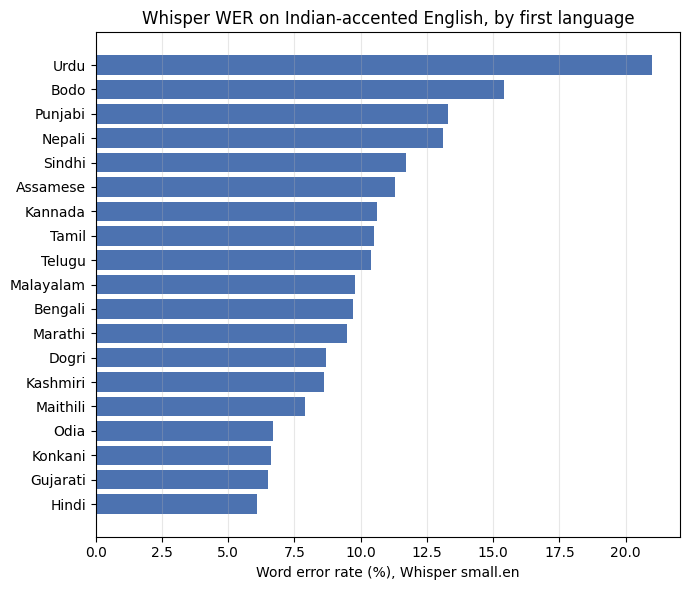

In [11]:
from huggingface_hub import login
login()   # paste your Hugging Face token when asked

import io, time, soundfile as sf, librosa, matplotlib.pyplot as plt
from datasets import load_dataset, Audio
from transformers import pipeline

sv = load_dataset("ai4bharat/Svarah", split="test")
meta = sv.remove_columns(["audio_filepath"]).to_pandas()
print(len(meta), "clips |", meta.primary_language.nunique(), "first languages")

# Balanced sample: up to 110 clips per first language
pick = (meta.groupby("primary_language", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), 110), random_state=42)))
print("Sampled clips:", len(pick))

def load16k(a):
    data, sr = sf.read(io.BytesIO(a) if isinstance(a, bytes) else a, dtype="float32")
    if data.ndim > 1:
        data = data.mean(axis=1)
    if sr != 16000:
        data = librosa.resample(data, orig_sr=sr, target_sr=16000)
    return data

raw = sv.cast_column("audio_filepath", Audio(decode=False)).select(pick.index.tolist())
arrays = [load16k(ex["audio_filepath"]["bytes"] or ex["audio_filepath"]["path"]) for ex in raw]
print(len(arrays), "clips decoded")

sv_path = f"{out}/svarah_asr.csv"
res = pick[["text", "primary_language", "native_place_state", "gender"]].reset_index(drop=True)
for size in ["small.en", "base.en"]:
    try:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", dtype=torch.float16, device=0)
    except TypeError:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", torch_dtype=torch.float16, device=0)
    t0 = time.time()
    res[size] = [o["text"].strip() for o in
                 asr([{"raw": x, "sampling_rate": 16000} for x in arrays], batch_size=16, chunk_length_s=30)]
    res.to_csv(sv_path, index=False)
    print("done", size, f"{time.time()-t0:.0f}s")
    del asr; torch.cuda.empty_cache()

# WER per first language
rows = []
for lang, g in res.groupby("primary_language"):
    rows.append({"first_language": lang, "clips": len(g),
                 "WER_small_%": round(wer(g.text, g["small.en"]), 1),
                 "WER_base_%": round(wer(g.text, g["base.en"]), 1)})
by_lang = pd.DataFrame(rows).sort_values("WER_small_%")
print(f"\nOverall Svarah WER: small.en {wer(res.text, res['small.en']):.1f}% | base.en {wer(res.text, res['base.en']):.1f}%")
print("(Medical dataset WER for comparison: small.en 10.4% | base.en 16.8%)\n")
print(by_lang.to_string(index=False))
by_lang.to_csv(f"{out}/svarah_wer_by_language.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(by_lang.first_language, by_lang["WER_small_%"], color="#4C72B0")
ax.set_xlabel("Word error rate (%), Whisper small.en"); ax.set_title("Whisper WER on Indian-accented English, by first language")
ax.grid(axis="x", alpha=.3); plt.tight_layout()
plt.savefig(f"{out}/fig2_svarah_wer_by_language.png", dpi=200); plt.show()

# Block 11: sanity check (a few seconds, no GPU)

In [12]:
import numpy as np, jiwer
res["duration"] = pick["duration"].values

def clip_wer(r, h):
    r, h = norm(r), norm(h)
    return np.nan if not r else jiwer.wer(r, h if h else "<empty>")

for s in ["small.en", "base.en"]:
    res[f"cw_{s}"] = [clip_wer(r, h) for r, h in zip(res.text, res[s])]
    res[f"ratio_{s}"] = [len(norm(h).split()) / max(1, len(norm(r).split())) for r, h in zip(res.text, res[s])]
    res[f"halluc_{s}"] = res[f"ratio_{s}"] > 1.5

print(f"Clips longer than 30 s: {(res.duration > 30).mean():.1%}")
for s in ["small.en", "base.en"]:
    h = res[f"halluc_{s}"]
    print(f"{s}: hallucinated clips {h.mean():.1%} | WER all {wer(res.text, res[s]):.1f}% "
          f"| WER without them {wer(res.text[~h], res[s][~h]):.1f}% | median clip WER {100*res[f'cw_{s}'].median():.1f}%")

rows = []
for lang, g in res.groupby("primary_language"):
    row = {"first_language": lang}
    for s, tag in [("small.en", "small"), ("base.en", "base")]:
        ok = ~g[f"halluc_{s}"]
        row[f"{tag}_WER"] = round(wer(g.text, g[s]), 1)
        row[f"{tag}_WER_clean"] = round(wer(g.text[ok], g[s][ok]), 1)
        row[f"{tag}_median"] = round(100 * g[f"cw_{s}"].median(), 1)
        row[f"{tag}_halluc_%"] = round(100 * g[f"halluc_{s}"].mean(), 1)
    rows.append(row)
check = pd.DataFrame(rows).sort_values("small_WER_clean")
pd.set_option("display.width", 220)
print("\n", check.to_string(index=False))
check.to_csv(f"{out}/svarah_wer_by_language_checked.csv", index=False)
res.to_csv(f"{out}/svarah_asr_with_checks.csv", index=False)

pd.set_option("display.max_colwidth", 110)
for s, lang in [("small.en", "Urdu"), ("base.en", "Malayalam")]:
    g = res[res.primary_language == lang].sort_values(f"cw_{s}", ascending=False).head(3)
    print(f"\nWorst {s} clips for {lang}:")
    for _, r in g.iterrows():
        print(f"  [{r.duration:.0f}s, clip WER {100*r[f'cw_{s}']:.0f}%]\n   CORRECT: {r.text[:200]}\n   WHISPER: {r[s][:200]}")

Clips longer than 30 s: 0.0%
small.en: hallucinated clips 2.5% | WER all 10.2% | WER without them 8.5% | median clip WER 0.0%
base.en: hallucinated clips 3.5% | WER all 27.7% | WER without them 11.1% | median clip WER 5.9%

 first_language  small_WER  small_WER_clean  small_median  small_halluc_%  base_WER  base_WER_clean  base_median  base_halluc_%
         Hindi        6.1              5.5           0.0             1.8       8.3             7.5          0.0            2.7
       Konkani        6.6              6.1           0.0             2.7      10.5             8.2          0.0            5.5
      Gujarati        6.5              6.4           0.0             0.9       7.7             7.7          0.0            0.0
          Odia        6.7              6.5           0.0             0.9      55.7            10.9          0.0            3.6
      Maithili        7.9              6.9           0.0             1.8      33.5             8.6          5.4            2.7
       Bengal

# Block 12: updated Figure 2, using the cleaned numbers (seconds)

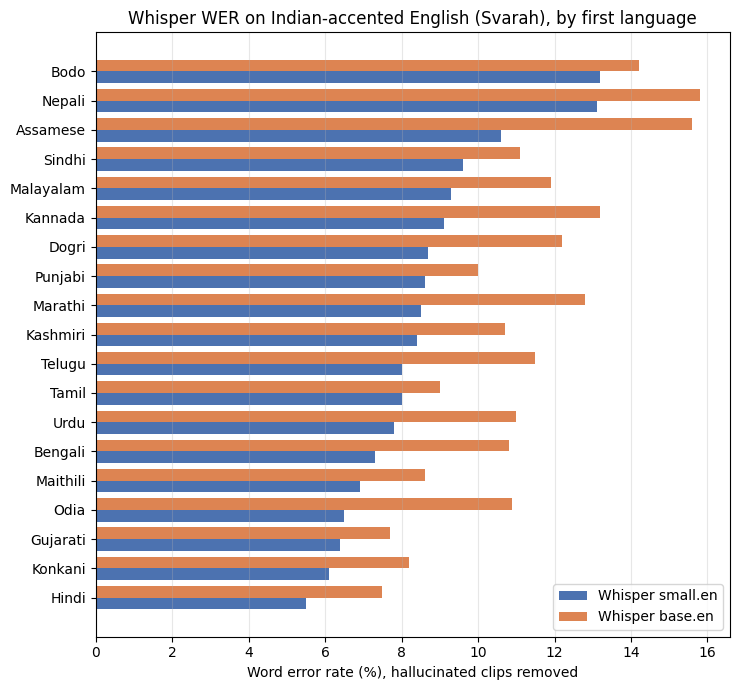

In [13]:
c = check.sort_values("small_WER_clean")
y = np.arange(len(c))
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(y - 0.2, c.small_WER_clean, height=0.4, label="Whisper small.en", color="#4C72B0")
ax.barh(y + 0.2, c.base_WER_clean, height=0.4, label="Whisper base.en", color="#DD8452")
ax.set_yticks(y); ax.set_yticklabels(c.first_language)
ax.set_xlabel("Word error rate (%), hallucinated clips removed")
ax.set_title("Whisper WER on Indian-accented English (Svarah), by first language")
ax.legend(); ax.grid(axis="x", alpha=.3); plt.tight_layout()
plt.savefig(f"{out}/fig2_svarah_wer_by_language.png", dpi=200); plt.show()

# Block 13: pilot recordings

In [15]:
import glob, subprocess, os, re
PILOT = "/content/drive/MyDrive/asr-triage/pilot"
SENT = {
 "E01": "My heart is pounding and it hurts.", "E02": "I have a sharp pain in my heart.",
 "E03": "I can't catch my breath.", "E04": "I am short of breath even when sitting.",
 "E05": "My chest feels very tight and heavy.", "E06": "It is hard to breathe when I lie down.",
 "E07": "I can't get enough air.", "E08": "I am gasping after climbing two steps.",
 "E09": "My left arm is numb and my jaw hurts.", "E10": "I feel like I am drowning on dry land.",
 "N01": "I feel tired because of the heat outside.", "N02": "It is hard to sleep at night.",
 "N03": "I have bad breath in the morning.", "N04": "My head hurts after reading for long.",
 "N05": "I hurt my knee playing cricket.", "N06": "My heel hurts when I walk.",
 "N07": "I have a runny nose and I sneeze a lot.", "N08": "My skin is dry and itchy.",
 "N09": "I have pain in my lower back.", "N10": "My hat feels tight on my forehead."}

files_found = sorted(f for f in glob.glob(f"{PILOT}/*") if re.match(r"[EN]\d\d_", os.path.basename(f)))
print(len(files_found), "pilot files found")

def to16k(path):
    wav = "/content/tmp_pilot.wav"
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path, "-ar", "16000", "-ac", "1", wav], check=True)
    data, _ = sf.read(wav, dtype="float32")
    return data

rows = [{"file": os.path.basename(f), "code": os.path.basename(f)[:3],
         "speaker": os.path.splitext(os.path.basename(f))[0].split("_")[1], "audio": to16k(f)} for f in files_found]
pilot = pd.DataFrame(rows)
pilot["truth"] = pilot.code.map(SENT)
pilot["is_emergency"] = pilot.code.str.startswith("E")

for size in SIZES:
    try:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", dtype=torch.float16, device=0)
    except TypeError:
        asr = pipeline("automatic-speech-recognition", model=f"openai/whisper-{size}", torch_dtype=torch.float16, device=0)
    pilot[size] = [o["text"].strip() for o in asr([{"raw": a, "sampling_rate": 16000} for a in pilot.audio], batch_size=8)]
    del asr; torch.cuda.empty_cache()

summary = []
for src in ["truth"] + SIZES:
    kw = pilot[src].apply(keyword_flag)
    rl = rules_flag(pilot[src])
    row = {"source": src, "WER_%": 0.0 if src == "truth" else round(wer(pilot.truth, pilot[src]), 1),
           "keyword_recall": kw[pilot.is_emergency].mean(), "keyword_false_alarm": kw[~pilot.is_emergency].mean(),
           "rules_recall": rl[pilot.is_emergency].mean(), "rules_false_alarm": rl[~pilot.is_emergency].mean()}
    if model is not None:
        be = pd.Series(predict(pilot[src]), index=pilot.index).isin(EMERGENCY)
        row.update({"bert_recall": be[pilot.is_emergency].mean(), "bert_false_alarm": be[~pilot.is_emergency].mean()})
    summary.append(row)
pilot_summary = pd.DataFrame(summary).round(2)
print("\n", pilot_summary.to_string(index=False))

pd.set_option("display.max_colwidth", 60)
print("\nPer sentence (truth vs Whisper small.en / tiny.en):")
print(pilot[["file", "truth", "small.en", "tiny.en"]].to_string(index=False))
pilot.drop(columns="audio").to_csv(f"{out}/pilot_results.csv", index=False)
pilot_summary.to_csv(f"{out}/pilot_summary.csv", index=False)

20 pilot files found


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]


   source  WER_%  keyword_recall  keyword_false_alarm  rules_recall  rules_false_alarm  bert_recall  bert_false_alarm
   truth    0.0             0.6                  0.1           0.0                0.0          0.6               0.3
small.en    2.1             0.6                  0.1           0.0                0.0          0.6               0.3
 base.en    2.8             0.6                  0.1           0.0                0.0          0.6               0.3
 tiny.en    2.8             0.6                  0.1           0.0                0.0          0.6               0.3

Per sentence (truth vs Whisper small.en / tiny.en):
      file                                     truth                                  small.en                                   tiny.en
E01_PS.m4a        My heart is pounding and it hurts.        My heart is pounding and it hurts.        My heart is pounding and it hurts.
E02_PS.m4a          I have a sharp pain in my heart.          I have a sharp pain in m

# Block 14: final figure with error bars, plus which sentences DistilBERT flagged wrongly

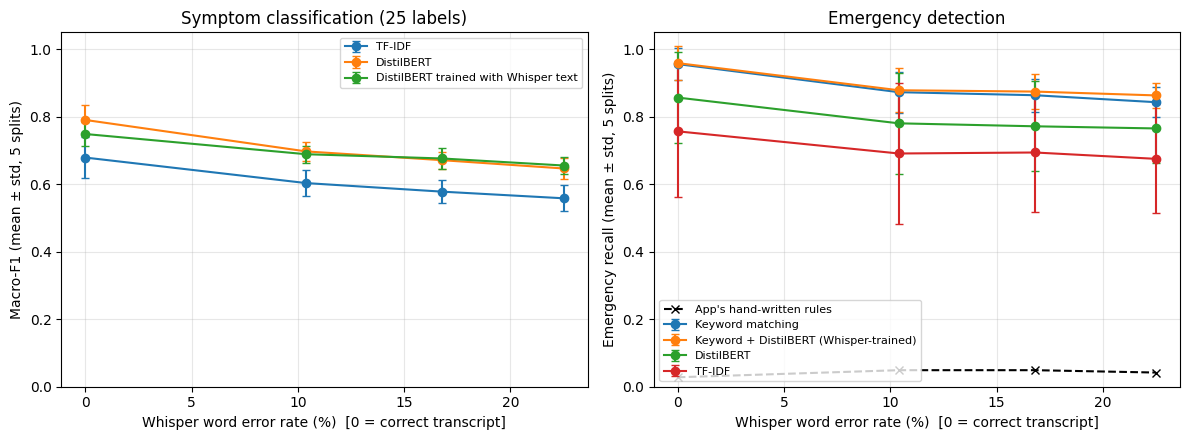

code                                     truth   distilbert_label
 E01        My heart is pounding and it hurts.        Heart hurts
 E02          I have a sharp pain in my heart.        Heart hurts
 E03                  I can't catch my breath.     Hard to breath
 E04   I am short of breath even when sitting.     Hard to breath
 E05      My chest feels very tight and heavy.     Hard to breath
 E06    It is hard to breathe when I lie down.     Hard to breath
 E07                   I can't get enough air.              Cough
 E08    I am gasping after climbing two steps.              Cough
 E09     My left arm is numb and my jaw hurts.          Foot ache
 E10    I feel like I am drowning on dry land.              Cough
 N01 I feel tired because of the heat outside.    Body feels weak
 N02             It is hard to sleep at night.     Hard to breath
 N03         I have bad breath in the morning.     Hard to breath
 N04     My head hurts after reading for long.          Head ache
 N05      

In [16]:
rep = pd.read_csv(f"{out}/repeated_splits.csv")
order = ["Correct (human)", "Whisper small.en", "Whisper base.en", "Whisper tiny.en"]
x = [0, 10.4, 16.8, 22.5]                     # WER on all 6,661 clips
rules = [0.028, 0.049, 0.049, 0.042]          # app's hand-written rules, all emergency clips

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, lab in [("TF-IDF", "TF-IDF"), ("DistilBERT", "DistilBERT"),
               ("DistilBERT+ASR (Fix A)", "DistilBERT trained with Whisper text")]:
    d = rep[rep.method == m].groupby("source").macro_f1.agg(["mean", "std"]).loc[order]
    axes[0].errorbar(x, d["mean"], yerr=d["std"], marker="o", capsize=3, label=lab)
axes[0].set_title("Symptom classification (25 labels)"); axes[0].set_ylabel("Macro-F1 (mean ± std, 5 splits)")
for m, lab in [("Keyword only", "Keyword matching"), ("Fix A + keyword", "Keyword + DistilBERT (Whisper-trained)"),
               ("DistilBERT", "DistilBERT"), ("TF-IDF", "TF-IDF")]:
    d = rep[rep.method == m].groupby("source").emerg_recall.agg(["mean", "std"]).loc[order]
    axes[1].errorbar(x, d["mean"], yerr=d["std"], marker="o", capsize=3, label=lab)
axes[1].plot(x, rules, "k--", marker="x", label="App's hand-written rules")
axes[1].set_title("Emergency detection"); axes[1].set_ylabel("Emergency recall (mean ± std, 5 splits)")
for ax in axes:
    ax.set_xlabel("Whisper word error rate (%)  [0 = correct transcript]")
    ax.set_ylim(0, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{out}/fig1_main_results.png", dpi=200); plt.show()

be = pd.Series(predict(pilot["small.en"]), index=pilot.index)
print(pilot.assign(distilbert_label=be)[["code", "truth", "distilbert_label"]].to_string(index=False))